# Раздел 1. Основы теории вероятностей
---

## Тема 3. Применение условных вероятностей в анализе данных
---

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine

### Описание данных

Для работы возьмём набор данных Wine. В нём собраны результаты химического анализа 178 образцов вина из одного региона Италии. Вина разделены на три класса (0, 1 и 2). Обычно эти данные используют, чтобы по составу вина определить его класс.

Источник: [Wine — UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/109/wine). Набор уже есть в sklearn.

In [2]:
wine = load_wine(as_frame=True)
df = wine.frame
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


В таблице 13 признаков и столбец `target`:

| Столбец | Описание |
|---|---|
| alcohol | Содержание алкоголя |
| malic_acid | Содержание яблочной кислоты |
| ash | Зольность |
| alcalinity_of_ash | Щёлочность золы |
| magnesium | Содержание магния |
| total_phenols | Общее содержание фенолов |
| flavanoids | Содержание флавоноидов |
| nonflavanoid_phenols | Содержание нефлавоноидных фенолов |
| proanthocyanins | Содержание проантоцианидинов |
| color_intensity | Интенсивность цвета |
| hue | Оттенок |
| od280/od315_of_diluted_wines | Отношение оптических плотностей при 280 и 315 нм |
| proline | Содержание пролина |
| target | Класс вина (0, 1 или 2) |

Посмотрим, сколько образцов в каждом классе и есть ли пропуски в данных.

In [3]:
print("Размер таблицы:", df.shape)
print("Количество пропусков:", df.isna().sum().sum())
df["target"].value_counts().sort_index()

Размер таблицы: (178, 14)
Количество пропусков: 0


target
0    59
1    71
2    48
Name: count, dtype: int64

### Условная вероятность

Допустим, мы случайно выбираем один образец из таблицы. Найдём вероятность того, что содержание алкоголя в нём не меньше 13%, если нам известен класс вина.

$A$ – содержание алкоголя не меньше 13%; $B_i$ – вино относится к классу $i$.

Для начала найдём обычную вероятность $P(A)$, не учитывая класс.

In [4]:
A = df["alcohol"] >= 13
P_A = A.mean()

print("Подходящих образцов:", A.sum())
print("P(A) =", round(P_A, 4))

Подходящих образцов: 92
P(A) = 0.5169


Под условие подошли 92 образца из 178. Получается, что вероятность равна примерно $0{,}517$.

Теперь найдём вероятность для класса 0 по формуле условной вероятности:

$P(A \mid B_0) = \frac{P(A \cap B_0)}{P(B_0)}$

In [5]:
B0 = df["target"] == 0
P_B0 = B0.mean()
P_AB0 = (A & B0).mean()

print("P(A | B0) =", round(P_AB0 / P_B0, 4))

P(A | B0) = 0.9661


Тот же результат можно получить проще: оставить только вина класса 0 и посчитать долю подходящих образцов среди них.

In [6]:
class0 = df[df["target"] == 0]
round((class0["alcohol"] >= 13).mean(), 4)

np.float64(0.9661)

Посчитаем условные вероятности сразу для всех трёх классов.

In [7]:
P_cond = A.groupby(df["target"]).mean()
P_cond.round(4)

target
0    0.9661
1    0.1127
2    0.5625
Name: alcohol, dtype: float64

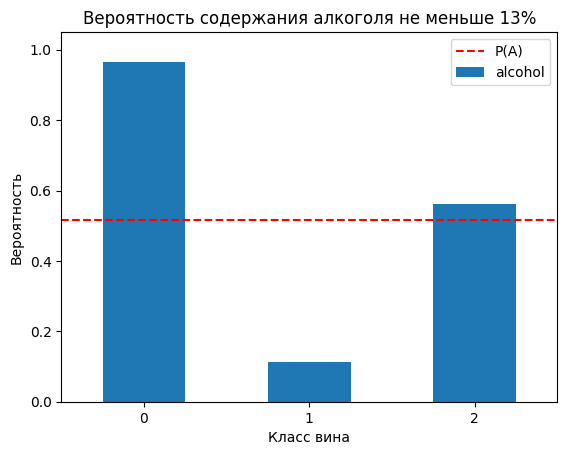

In [8]:
P_cond.plot(kind="bar", rot=0)
plt.axhline(P_A, color="red", linestyle="--", label="P(A)")
plt.xlabel("Класс вина")
plt.ylabel("Вероятность")
plt.title("Вероятность содержания алкоголя не меньше 13%")
plt.ylim(0, 1.05)
plt.legend()
plt.show()

По графику видно, что в классе 0 почти все вина содержат не меньше 13% алкоголя (57 из 59), а в классе 1 таких вин всего 8 из 71. Если мы знаем класс вина, то можем оценить вероятность точнее, чем по всей таблице.

### Формула полной вероятности

Попробуем найти $P(A)$ другим способом. Так как каждый образец относится к одному из трёх классов, можно использовать формулу полной вероятности:

$P(A) = P(B_0)P(A\mid B_0) + P(B_1)P(A\mid B_1) + P(B_2)P(A\mid B_2)$

Сначала найдём долю каждого класса, а затем умножим её на соответствующую условную вероятность.

In [9]:
P_B = df["target"].value_counts(normalize=True).sort_index()
P_full = (P_B * P_cond).sum()

print("По формуле полной вероятности:", round(P_full, 4))
print("Напрямую из данных:", round(P_A, 4))

По формуле полной вероятности: 0.5169
Напрямую из данных: 0.5169


### Формула Байеса

Теперь рассмотрим обратную ситуацию. Мы знаем, что в выбранном вине содержание алкоголя не меньше 13%, но не знаем его класс. Найдём вероятности классов по формуле Байеса:

$P(B_i\mid A) = \frac{P(A\mid B_i)P(B_i)}{P(A)}$

In [10]:
P_bayes = P_cond * P_B / P_A
P_bayes.round(4)

target
0    0.6196
1    0.0870
2    0.2935
dtype: float64

Проверим результат: отберём все подходящие вина и посмотрим, какая часть из них относится к каждому классу.

In [11]:
df[A]["target"].value_counts(normalize=True).sort_index().round(4)

target
0    0.6196
1    0.0870
2    0.2935
Name: proportion, dtype: float64

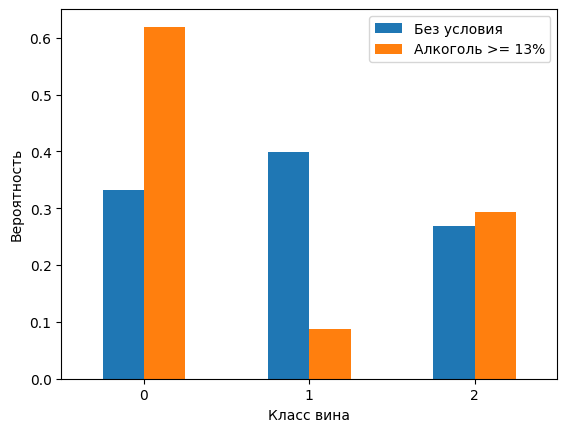

In [12]:
probs = pd.DataFrame({"Без условия": P_B, "Алкоголь >= 13%": P_bayes})
probs.plot(kind="bar", rot=0)
plt.xlabel("Класс вина")
plt.ylabel("Вероятность")
plt.show()

### Вывод

Если выбирать вино из всей таблицы, то чаще всего встречается класс 1. Но если известно, что содержание алкоголя не меньше 13%, то наиболее вероятен класс 0 (около 62%). Таким образом, дополнительная информация меняет нашу оценку вероятности. Это вывод по данному набору данных, а не по всем винам.